<a href="https://colab.research.google.com/github/eternitvy/ML_26/blob/main/PBL/dataset_gabungan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV3Small
import matplotlib.pyplot as plt
import os

# Hubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

print("TensorFlow Version:", tf.__version__)
print("Google Drive berhasil dihubungkan!")

Mounted at /content/drive
TensorFlow Version: 2.21.0
Google Drive berhasil dihubungkan!


In [2]:
# SESUAIKAN path di bawah ini dengan lokasi folder dataset kamu di Drive
train_dir = '/content/drive/MyDrive/Dataset_PBL/Banana_Images/Gabungan_Dataset/train'
test_dir = '/content/drive/MyDrive/Dataset_PBL/Banana_Images/Gabungan_Dataset/test'

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 4         # Grade A, B, C, D

print("Memuat dataset...")

# Load Dataset menggunakan image_dataset_from_directory
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False
)

class_names = train_ds.class_names
print("\nDaftar Kelas (Grades):", class_names)

# Optimasi performa pemuatan data dengan prefetch
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)
print("Dataset siap digunakan!")

Memuat dataset...
Found 8002 files belonging to 4 classes.
Found 2000 files belonging to 4 classes.

Daftar Kelas (Grades): ['Grade A', 'Grade B', 'Grade C', 'Grade D']
Dataset siap digunakan!


In [3]:
print("Membangun model MobileNetV3Small...")

# Menggunakan MobileNetV3Small sebagai base model
base_model = MobileNetV3Small(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze base model terlebih dahulu
base_model.trainable = False

# Menyusun arsitektur model akhir
inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.applications.mobilenet_v3.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = models.Model(inputs, outputs)

# Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Membangun model MobileNetV3Small...
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 7, 7, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         2,308 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 941,428 (3.59 MB)

 Trainable params: 2,308 (9.02 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [4]:
EPOCHS = 15  # Jumlah epoch bisa disesuaikan

print(f"Memulai proses training selama {EPOCHS} epoch...")
history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS
)
print("Training selesai!")

Memulai proses training selama 15 epoch...
Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 2809s 11s/step - accuracy: 0.7979 - loss: 0.5213 - val_accuracy: 0.9295 - val_loss: 0.2427
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 696s 3s/step - accuracy: 0.9203 - loss: 0.2355 - val_accuracy: 0.9510 - val_loss: 0.1712
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 161s 639ms/step - accuracy: 0.9360 - loss: 0.1871 - val_accuracy: 0.9610 - val_loss: 0.1422
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 159s 632ms/step - accuracy: 0.9458 - loss: 0.1599 - val_accuracy: 0.9575 - val_loss: 0.1343
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 206s 644ms/step - accuracy: 0.9496 - loss: 0.1481 - val_accuracy: 0.9615 - val_loss: 0.1195
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 205s 660ms/step - accuracy: 0.9516 - loss: 0.1427 - val_accuracy: 0.9615 - val_loss: 0.1198
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 164s 653ms/step - accuracy: 0.9553 - loss: 0.1302 - val_accuracy: 0.9670 - val_loss: 0.1024
Epoch 8/15
251/251 ━━━━━━━━━━━━━━━━━━

Mengevaluasi model pada test set...
63/63 ━━━━━━━━━━━━━━━━━━━━ 31s 494ms/step - accuracy: 0.9655 - loss: 0.0983

Akurasi pada Test Set: 96.55%
Model berhasil disimpan sebagai 'banana_mobilenetv3_model.keras'


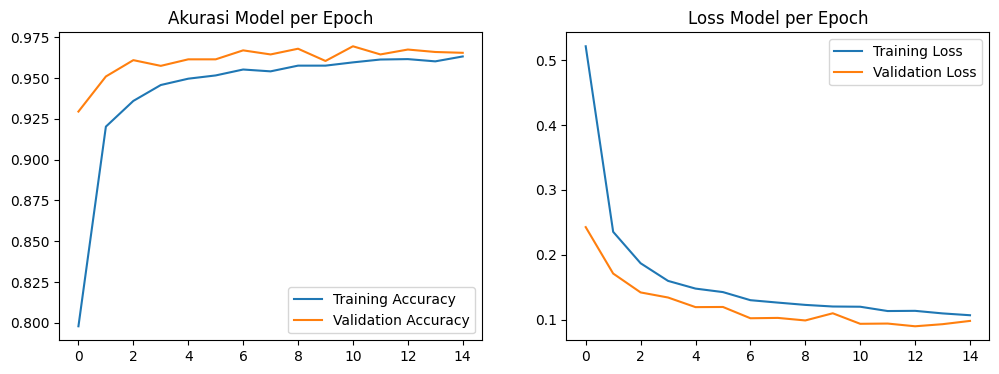

In [5]:
# Evaluasi Model
print("Mengevaluasi model pada test set...")
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nAkurasi pada Test Set: {test_acc * 100:.2f}%")

# Simpan Model
model_filename = 'banana_mobilenetv3_model.keras'
model.save(model_filename)
print(f"Model berhasil disimpan sebagai '{model_filename}'")

# Visualisasi Grafik Akurasi & Loss
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Akurasi Model per Epoch')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Loss Model per Epoch')
plt.show()

Mengambil label asli dan melakukan prediksi pada test set...
63/63 ━━━━━━━━━━━━━━━━━━━━ 34s 516ms/step

=== Classification Report ===
              precision    recall  f1-score   support

     Grade A       0.94      0.99      0.96       500
     Grade B       0.98      0.89      0.94       500
     Grade C       0.96      0.98      0.97       500
     Grade D       0.99      0.99      0.99       500

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



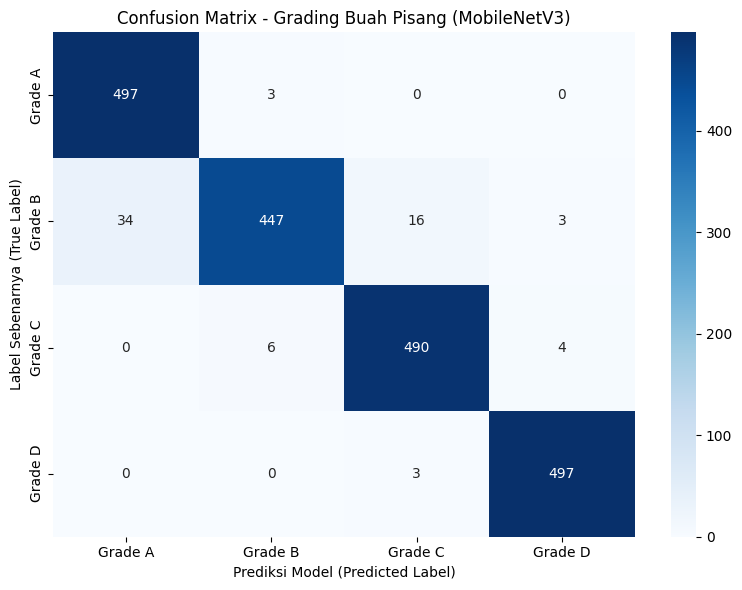

In [6]:
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

print("Mengambil label asli dan melakukan prediksi pada test set...")

# 1. Ambil seluruh label asli (true labels) dari test_ds
y_true = []
for images, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
y_true = np.array(y_true)

# 2. Lakukan prediksi pada test_ds
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Tampilkan Classification Report (Precision, Recall, F1-Score)
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names))

# 4. Hitung dan Visualisasikan Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Grading Buah Pisang (MobileNetV3)')
plt.xlabel('Prediksi Model (Predicted Label)')
plt.ylabel('Label Sebenarnya (True Label)')
plt.tight_layout()
plt.show()

Model berhasil dimuat!

Silakan unggah foto pisang baru (di luar dataset):


Saving images-3.jpeg to images-3.jpeg


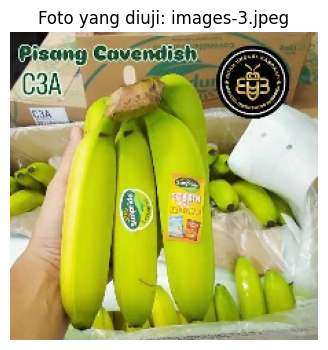

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step

 HASIL PREDIKSI MODEL:
Prediksi Kelas : Grade B
Tingkat Keyakinan (Confidence): 61.18%


In [11]:
import numpy as np
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.pyplot as plt

# 1. Muat ulang model yang sudah disimpan sebelumnya (kalau sel sebelumnya tertutup/reset)
# (Opsional, pastikan model 'banana_mobilenetv3_model.keras' ada di direktori kerja Colab)
try:
    model = tf.keras.models.load_model('banana_mobilenetv3_model.keras')
    print("Model berhasil dimuat!")
except:
    pass

# 2. Upload foto baru dari komputer kamu
print("\nSilakan unggah foto pisang baru (di luar dataset):")
uploaded = files.upload()

for fn in uploaded.keys():
  path = fn

  # 3. Load dan sesuaikan ukuran gambar dengan input MobileNetV3 (224x224)
  img = image.load_img(path, target_size=(224, 224))

  # Tampilkan gambar yang kamu upload di Colab
  plt.figure(figsize=(4, 4))
  plt.imshow(img)
  plt.axis('off')
  plt.title(f"Foto yang diuji: {fn}")
  plt.show()

  # 4. Ubah gambar menjadi array numpy
  x = image.img_to_array(img)
  x = np.expand_dims(x, axis=0) # Tambah dimensi batch (1, 224, 224, 3)

  # 5. Lakukan Prediksi
  predictions = model.predict(x)
  score = tf.nn.softmax(predictions[0]) # Mengubah output mentah menjadi probabilitas (0 - 100%)

  # Ambil kelas dengan predniksi tertinggi
  predicted_class_idx = np.argmax(predictions[0])

  # Daftar nama kelas sesuai urutan folder dataset training kamu
  # (Pastikan urutannya sama persis dengan train_ds.class_names)
  class_names = ['Grade A', 'Grade B', 'Grade C', 'Grade D']

  print("\n" + "="*30)
  print(f" HASIL PREDIKSI MODEL:")
  print("="*30)
  print(f"Prediksi Kelas : {class_names[predicted_class_idx]}")
  print(f"Tingkat Keyakinan (Confidence): {np.max(predictions[0]) * 100:.2f}%")
  print("="*30)